# Tomorrow's air in London: the gaps someone filled in for you

**On a table with its gaps filled in, every forecast of London's fine particles looks about a fifth better than it is. The three monitors that reported nothing all winter come out as the easiest in the city to forecast.**

Air quality monitors break down, get serviced and lose their connection, so a table of readings has empty cells. Before the table reaches a model somebody fills them, most often by repeating the last reading. For a forecaster's inputs that is fair: at forecast time the last reading is all there is. For the answers a forecast is scored against, it is not: a filled-in answer never happened, and it rewards whichever forecast moves least. TimeGym will not cut a test case through an empty cell, and this notebook starts from that refusal.

*Data: fine particles (PM2.5) for every hour at 24 monitors in London, November 2017 to March 2018, from the KDD Cup 2018 data in the Monash Time Series Forecasting Archive ([source and license](data/README.md#london-air)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import textwrap

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import ListedColormap
from sklearn.linear_model import LinearRegression

from timegym import LastValueForecaster, Pipeline, SeasonalLastValueForecaster, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The job

Every midnight, forecast the next 24 hours of fine particles at each monitor. The table has one row per hour and one column per monitor, under the network's site codes. Readings are in micrograms per cubic meter.

,CD1,BL0,GR4,MY7,HV1,GN3,GR9,LW2
time,,,,,,,,
2017-11-01 00:00:00,17.6,15.0,NaN,15.7,10.8,10.5,7.7,9.8
2017-11-01 01:00:00,13.9,13.5,NaN,16.6,9.2,9.5,6.8,12.2
2017-11-01 02:00:00,15.2,11.2,NaN,13.3,7.3,5.5,5.5,11.6


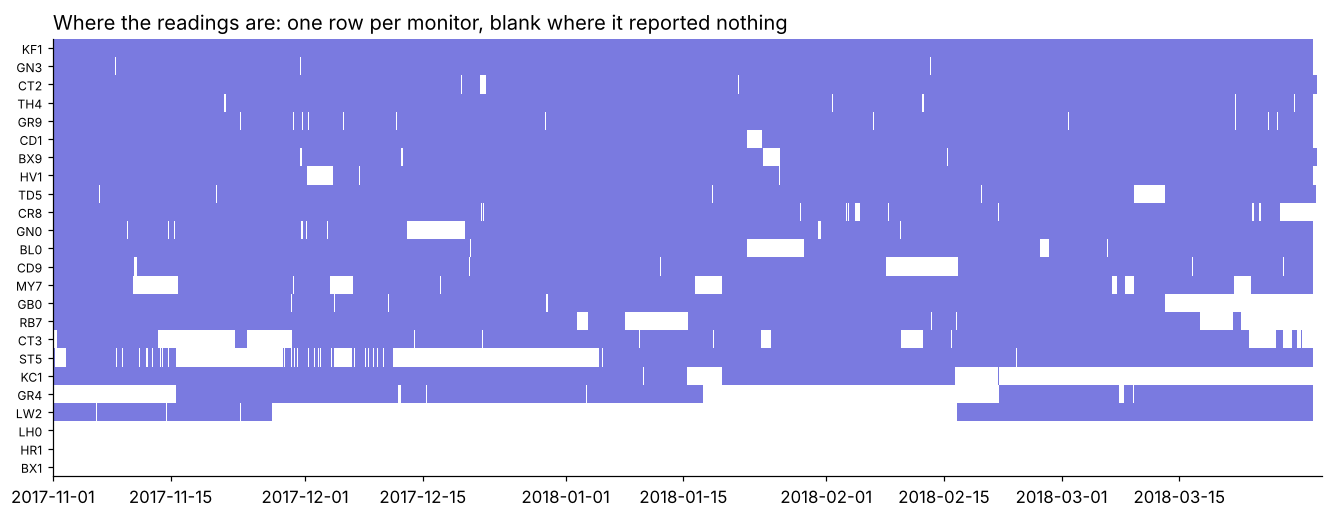

24 monitors, 3,624 hours, 01 November 2017 to 31 March 2018.
Empty cells: 23%. Monitors with no reading at all: LH0, HR1, BX1.
Average reading: 12.7 micrograms per cubic meter.


In [2]:
air = load("london-air")
display(air.iloc[:3, :8])

reported = air.notna().mean().sort_values(ascending=False)
edges = mdates.date2num([air.index[0], air.index[-1]])
fig, ax = plt.subplots(figsize=(12, 4.6), layout="constrained")
ax.imshow(air[reported.index].notna().T, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["white", "#7A7AE0"]), extent=[edges[0], edges[1], len(reported), 0])
ax.xaxis_date()
ax.set_yticks(np.arange(len(reported)) + 0.5, reported.index, fontsize=8)
ax.set(title="Where the readings are: one row per monitor, blank where it reported nothing")
plt.show()

empty = air.isna().to_numpy().mean()
silent = list(reported.index[reported == 0])
print(f"{air.shape[1]} monitors, {len(air):,} hours, {air.index[0]:%d %B %Y} to {air.index[-1]:%d %B %Y}.")
print(f"Empty cells: {empty:.0%}. Monitors with no reading at all: {', '.join(silent)}.")
print(f"Average reading: {np.nanmean(air.to_numpy()):.1f} micrograms per cubic meter.")
assert round(100 * empty) == 23 and sorted(silent) == ["BX1", "HR1", "LH0"]

Almost a quarter of the cells are empty. Three monitors reported nothing in these five months, and several others were silent for weeks at a time.

## TimeGym stops at the first empty cell

A test case is a piece of history and the 24 hours that followed it. We ask for one case per midnight from 1 December, which leaves every forecast at least 30 days of history, starting with the first monitor in the table.

In [3]:
horizon, first = 24, 30 * 24   # forecast a day; keep 30 days of history before the first forecast
midnights = [row for row in range(first, len(air) - horizon + 1) if air.index[row].hour == 0]
print(f"{len(midnights)} midnights, {air.index[midnights[0]]:%d %B %Y} to {air.index[midnights[-1]]:%d %B %Y}.")

try:
    cases_from_series(air[["CD1"]], origins=midnights, horizon=horizon, name="CD1")
except ValueError as error:
    print(textwrap.fill(f"TimeGym: {error}", width=72))
assert len(midnights) == 121

121 midnights, 01 December 2017 to 31 March 2018.
TimeGym: origin 720: the history has missing or infinite values; fill or
drop them before cutting cases


Row 720 is the first midnight we asked for, and somewhere in the 30 days before it this monitor has an empty cell. TimeGym does not guess what to put there. It names the choice: fill or drop.

## The easy way out: fill everything

Filling is quicker, and there is a ready-made rule. The archive that publishes this table also publishes it "without missing values": a monitor's hours before its first reading are set to zero, and every later empty hour repeats the last reading. Applied to the archive's whole file, the line below gives that published file value for value ([how that was checked](data/README.md#london-air)). Here it is applied to the five months of the sample, so a monitor that was already silent on 1 November starts at zero.

Four forecasters, from doing nothing to a regression:

- **Same as the last hour** repeats the latest reading for all 24 hours.
- **Same hours as yesterday** repeats the last 24 readings.
- **Average of the last week** gives one number for all 24 hours.
- **Regression on the last 24 hours** is a linear regression, refit at each midnight on the monitor's history.

In [4]:
filled = air.ffill().fillna(0.0)   # zero before a monitor's first reading, then repeat the last reading


class RecentAverage:
    "The average of the last so many hours, for every hour ahead."

    def __init__(self, hours):
        self.hours = hours

    def fit(self, history):
        self.level_ = float(np.asarray(history)[-self.hours:].mean())
        return self

    def predict(self, dates):
        return np.full(len(dates), self.level_)


forecasters = {
    "Same as the last hour": Pipeline(LastValueForecaster()),
    "Same hours as yesterday": Pipeline(SeasonalLastValueForecaster(period=24)),
    "Average of the last week": Pipeline(RecentAverage(7 * 24)),
    "Regression on the last 24 hours": Pipeline(LinearRegression(), window_length=24),
}
regression, last_hour = "Regression on the last 24 hours", "Same as the last hour"


def backtest(table):
    # Every forecaster at every monitor and midnight. Returns one row per case:
    # the average miss over its 24 hours, in micrograms per cubic meter.
    rows = []
    for monitor in table.columns:
        cases = cases_from_series(table[[monitor]], origins=midnights, horizon=horizon, name=monitor)
        for name, pipeline in forecasters.items():
            run = pipeline.run(cases=cases)
            counts = run.report.summary["status_counts"]
            assert counts["FAIL"] == 0 and counts["ERROR"] == 0, (monitor, name, counts)
            rows += [(monitor, row, name, entry.result.metrics["mae"]) for row, entry in zip(midnights, run.cases)]
    return pd.DataFrame(rows, columns=["monitor", "row", "forecaster", "miss"])


scores = backtest(filled)
on_filled = scores.groupby("forecaster").miss.mean().sort_values()
display(on_filled.round(2).rename("Average miss").rename_axis("On the filled table").to_frame())
print(f"{scores.groupby(['monitor', 'row']).ngroups:,} cases for each forecaster, and every run passed the output checks.")
assert on_filled.index[0] == regression and on_filled.round(2).tolist() == [4.35, 4.73, 5.65, 5.66]

,Average miss
On the filled table,
Regression on the last 24 hours,4.35
Same as the last hour,4.73
Same hours as yesterday,5.65
Average of the last week,5.66


2,904 cases for each forecaster, and every run passed the output checks.


Everything ran, nothing failed, and the regression is ahead: it misses by 4.35 micrograms, on readings that average about 13. That would go in a report.

## Look at the cases

The run keeps every case with its score, so before believing an average we can look at what went into it. Two questions: at which monitors is the forecast best, and how often is a forecast exactly right?

Monitors where the regression misses least, on the filled table:
  BX1 0.00   HR1 0.00   LH0 0.00   LW2 3.48   GR4 3.84

Cases with a miss of exactly zero, out of 2,904:
  Same as the last hour            634
  Same hours as yesterday          598
  Average of the last week         494
  Regression on the last 24 hours  363


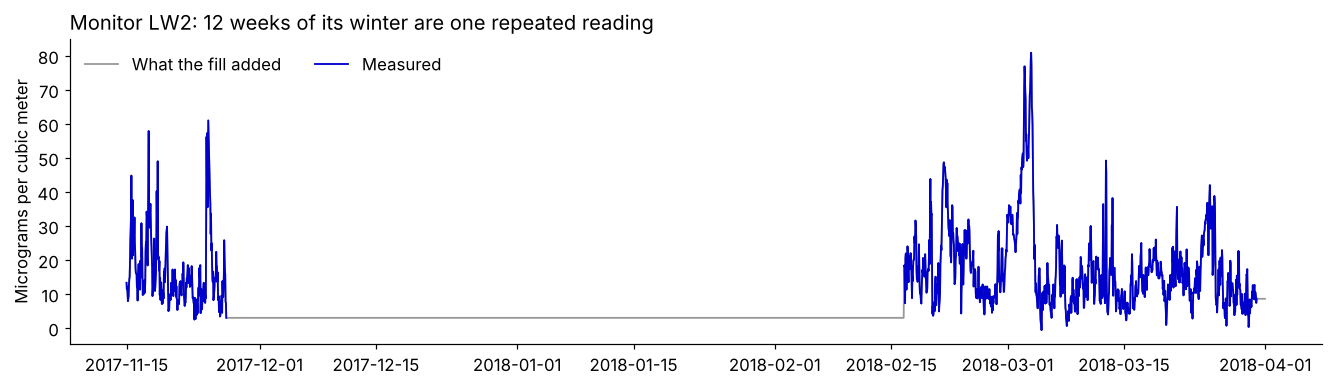

In [5]:
by_monitor = scores[scores.forecaster == regression].groupby("monitor").miss.mean().sort_values()
print("Monitors where the regression misses least, on the filled table:")
print("  " + "   ".join(f"{monitor} {miss:.2f}" for monitor, miss in by_monitor.head(5).items()))

exact = scores[scores.miss == 0].groupby("forecaster").size()
cases_each = len(scores) // len(forecasters)
print(f"\nCases with a miss of exactly zero, out of {cases_each:,}:")
for name in forecasters:
    print(f"  {name:32s}{exact.get(name, 0):4d}")

winter = slice("2017-11-15", "2018-03-31")
quiet = air["LW2"].isna()
weeks = quiet.groupby((~quiet).cumsum()).sum().max() / (7 * 24)   # the longest stretch with no reading
fig, ax = plt.subplots(figsize=(12, 3.4), layout="constrained")
ax.plot(filled.loc[winter, "LW2"], color="0.6", linewidth=1.2, label="What the fill added")
ax.plot(air.loc[winter, "LW2"], color="#0000CC", linewidth=1.2, label="Measured")
ax.set(title=f"Monitor LW2: {weeks:.0f} weeks of its winter are one repeated reading", ylabel="Micrograms per cubic meter")
ax.legend(loc="upper left", ncols=2)
plt.show()

assert by_monitor.index[:3].isin(["BX1", "HR1", "LH0"]).all() and by_monitor.iloc[2] == 0 and by_monitor.index[3] == "LW2"
assert exact[last_hour] == 634 and cases_each == 2904 and round(by_monitor["LW2"], 2) == 3.48
assert 11 < weeks < 12.5 and air["LW2"].loc["2017-12-01":"2018-02-10"].isna().all()

The three best-forecast monitors in London are the three that reported nothing. Their filled columns are zero from start to finish, and every forecaster gets zero exactly right. The fourth, LW2, was silent from the end of November to the middle of February.

"Same as the last hour" is exactly right for a whole day 634 times, more than one case in five. No forecast of the air does that. On those days there was nothing to forecast: the answers are the last reading, repeated, and a forecaster that repeats the last reading matches them to the decimal.

## Fill the history, never the answers

The fix is to treat the two halves of a case differently.

- **The history** may be filled. At midnight a forecaster has what the monitor reported and nothing else, so carrying the last reading forward is what a live system would do too.
- **The answers** may not. A day counts only if all 24 of its hours were measured.

Each case is marked with how many of its 24 answers were real readings, and then scored again by group.

In [6]:
measured_hours = {(monitor, row): int(air[monitor].iloc[row:row + horizon].notna().sum())
                  for monitor in air.columns for row in midnights}
scores["measured"] = [measured_hours[key] for key in zip(scores.monitor, scores.row)]
scores["answers"] = np.select([scores.measured == horizon, scores.measured == 0],
                              ["All measured", "None measured"], "Partly")

groups = ["All measured", "Partly", "None measured"]
by_group = scores.pivot_table(index="forecaster", columns="answers", values="miss").loc[on_filled.index, groups]
sizes = scores[scores.forecaster == regression].answers.value_counts()[groups]
print("Cases:  " + ",  ".join(f"{group.lower()} {size:,}" for group, size in sizes.items()))
display(by_group.round(2).rename_axis(index="Average miss", columns="Answers of the case"))

real = scores[scores.measured == horizon]
compare = pd.DataFrame({"Filled table": on_filled, "Measured days": real.groupby("forecaster").miss.mean()}).loc[on_filled.index]
higher = compare["Measured days"] / compare["Filled table"] - 1
compare["Higher by"] = (100 * higher).round().astype(int).astype(str) + "%"
display(compare.round(2).rename_axis("Average miss"))
flattered = 1 - compare["Filled table"] / compare["Measured days"]

assert sizes.tolist() == [2096, 174, 634] and compare["Measured days"].round(2).tolist() == [5.40, 6.08, 7.23, 7.07]
assert by_group.loc[last_hour, "None measured"] == 0 and by_group.loc[regression, "None measured"] > 0
assert (real.miss > 0).all() and higher.between(0.235, 0.295).all() and flattered.between(0.19, 0.225).all()

Cases:  all measured 2,096,  partly 174,  none measured 634


Answers of the case,All measured,Partly,None measured
Average miss,,,
Regression on the last 24 hours,5.40,4.91,0.71
Same as the last hour,6.08,5.67,0.00
Same hours as yesterday,7.23,6.57,0.17
Average of the last week,7.07,6.58,0.78


,Filled table,Measured days,Higher by
Average miss,,,
Regression on the last 24 hours,4.35,5.40,24%
Same as the last hour,4.73,6.08,29%
Same hours as yesterday,5.65,7.23,28%
Average of the last week,5.66,7.07,25%


On days that were measured, the regression misses by 5.40 micrograms, not 4.35. Every forecaster's real miss is 24% to 29% higher than the filled table said. Put the other way round, the filled table made each one look about a fifth better than it is. A promise made on the first number would have been broken by the first week of real forecasts.

The filled days also tilt the comparison. On days with nothing measured, doing nothing scores a perfect zero, and a forecaster that moves at all is charged for it: the regression, which drifts back toward the monitor's usual level, picks up a miss there that "Same as the last hour" does not.

## Monitor by monitor

An average over the city hides where the damage is. Each monitor below is drawn twice: its miss on the filled table, and its miss on the days it measured in full.

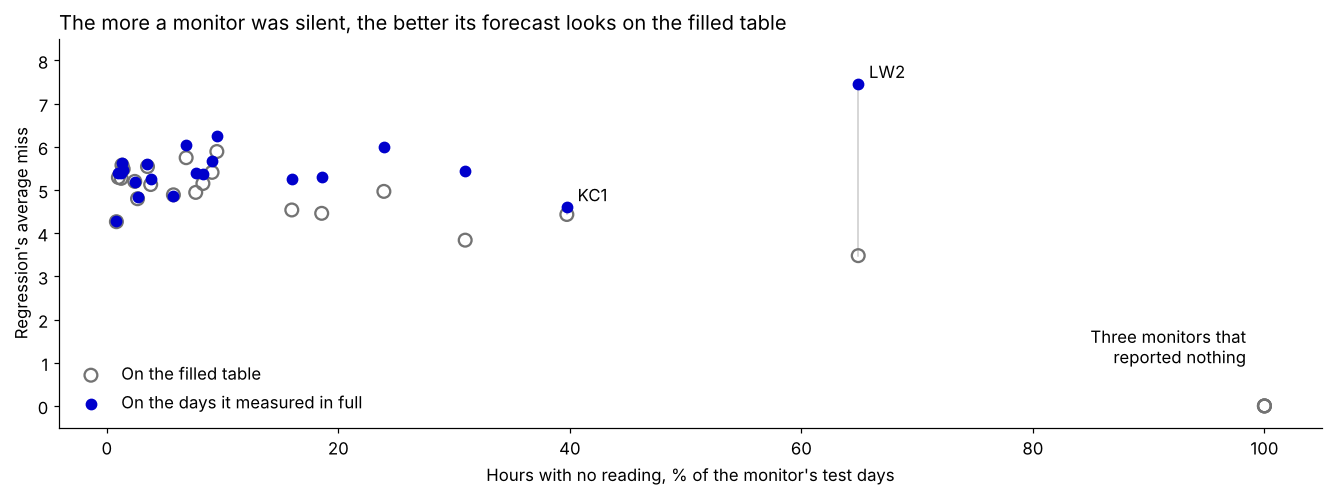

Monitors that measured at least one full day: 21 of 24.
Rank correlation of a monitor's miss with its share of silent hours:
  on the filled table -0.62,   on measured days +0.26

LW2 on the filled table: 3.48, the lowest of the 21 working monitors.
LW2 on its 42 measured days: 7.45. On those same days the middle one
  of 14 other monitors missed by 6.53, and 2 of them by more than LW2.


In [7]:
silent_share = 100 * (1 - scores[scores.forecaster == regression].groupby("monitor").measured.mean() / horizon)
monitors = pd.DataFrame({
    "silent": silent_share,
    "filled": scores[scores.forecaster == regression].groupby("monitor").miss.mean(),
    "measured": real[real.forecaster == regression].groupby("monitor").miss.mean(),
    "days": real[real.forecaster == regression].groupby("monitor").size(),
})

fig, ax = plt.subplots(figsize=(12, 4.4), layout="constrained")
ax.scatter(monitors.silent, monitors.filled, s=70, facecolors="none", edgecolors="0.45", linewidths=1.5, label="On the filled table")
ax.scatter(monitors.silent, monitors.measured, s=45, color="#0000CC", label="On the days it measured in full")
for monitor in ["LW2", "KC1"]:
    ax.plot([monitors.silent[monitor]] * 2, [monitors.filled[monitor], monitors.measured[monitor]], color="0.8", linewidth=1, zorder=0)
    ax.annotate(monitor, (monitors.silent[monitor], monitors.measured[monitor]), xytext=(7, 4), textcoords="offset points")
ax.annotate("Three monitors that\nreported nothing", (100, 0), xytext=(-12, 28), textcoords="offset points", ha="right")
ax.set(title="The more a monitor was silent, the better its forecast looks on the filled table",
       xlabel="Hours with no reading, % of the monitor's test days", ylabel="Regression's average miss", ylim=(-0.5, 8.5))
ax.legend(loc="lower left")
plt.show()

working = monitors.dropna()
print(f"Monitors that measured at least one full day: {len(working)} of {len(monitors)}.")
print("Rank correlation of a monitor's miss with its share of silent hours:")
print(f"  on the filled table {monitors.silent.corr(monitors.filled, method='spearman'):+.2f},"
      f"   on measured days {working.silent.corr(working.measured, method='spearman'):+.2f}")

lw2_days = set(real[real.monitor == "LW2"].row)
others = real[(real.forecaster == regression) & real.row.isin(lw2_days) & (real.monitor != "LW2")]
others = others.groupby("monitor").miss.agg(["mean", "size"])
others = others[others["size"] >= 0.8 * len(lw2_days)]["mean"]
print(f"\nLW2 on the filled table: {monitors.filled['LW2']:.2f}, the lowest of the {len(working)} working monitors.")
print(f"LW2 on its {monitors.days['LW2']:.0f} measured days: {monitors.measured['LW2']:.2f}. On those same days the middle one")
print(f"  of {len(others)} other monitors missed by {others.median():.2f}, and {(others > monitors.measured['LW2']).sum()} of them by more than LW2.")

assert working.filled.idxmin() == "LW2" and len(working) == 21 and monitors.days["LW2"] == 42
assert round(monitors.measured["LW2"], 2) == 7.45 and round(others.median(), 2) == 6.53 and (others > monitors.measured["LW2"]).sum() == 2
assert monitors.silent.corr(monitors.filled, method="spearman") < -0.5 < 0 < working.silent.corr(working.measured, method="spearman")

On the filled table a monitor's score is to a large part a record of how long it was silent. LW2 looks like the easiest working monitor in London at 3.48. On the 42 days it measured, the regression missed by 7.45, more than twice that, and only two of the 14 monitors that measured those same days were harder. Anyone ranking monitors, or deciding where a forecast is good enough to publish, would have been reading a list ordered by downtime.

## Which forecaster for which monitor?

A filled table can also pick the wrong forecaster. For each monitor we take the forecaster with the lowest miss, once on each kind of table. Then, because the monitors share their weather, we average the gap between the regression and "Same as the last hour" over the monitors for each day and put an interval on those daily gaps.

In [8]:
def winners(rows):
    return rows.pivot_table(index="monitor", columns="forecaster", values="miss").loc[working.index].idxmin(axis=1)


choice = pd.DataFrame({"Filled table": winners(scores), "Measured days": winners(real)})
changed = choice[choice["Filled table"] != choice["Measured days"]]
print(f"On measured days the regression is best at {(choice['Measured days'] == regression).sum()} of {len(choice)} monitors.")
print(f"On the filled table '{changed['Filled table'].iloc[0]}' wins at {len(changed)}: {', '.join(changed.index)}.")

paired = real.pivot_table(index=["monitor", "row"], columns="forecaster", values="miss")
gap = paired[last_hour] - paired[regression]
print("\nExtra miss of 'Same as the last hour' over the regression,")
print("on measured days:")
for monitor in changed.index:
    interval = paired_t_interval(gap[monitor].to_numpy())
    print(f"  {monitor}: {interval['mean']:.2f} (interval {interval['ci95'][0]:.2f} to {interval['ci95'][1]:.2f}, {interval['n']} days)")
city = paired_t_interval(gap.groupby("row").mean().to_numpy())
print(f"  all monitors, day by day: {city['mean']:.2f} (interval {city['ci95'][0]:.2f} to {city['ci95'][1]:.2f}, {city['n']} days)")

kc1 = paired_t_interval(gap["KC1"].to_numpy())
assert (choice["Measured days"] == regression).all() and list(changed.index) == ["KC1", "LW2"]
assert (changed["Filled table"] == last_hour).all() and kc1["ci95"][0] > 0 and city["ci95"][0] > 0
assert round(city["mean"], 2) == 0.71

On measured days the regression is best at 21 of 21 monitors.
On the filled table 'Same as the last hour' wins at 2: KC1, LW2.



Extra miss of 'Same as the last hour' over the regression,
on measured days:
  KC1: 1.02 (interval 0.21 to 1.83, 66 days)
  LW2: 0.49 (interval -0.75 to 1.73, 42 days)
  all monitors, day by day: 0.71 (interval 0.23 to 1.19, 120 days)


At two monitors the filled table hands the job to "Same as the last hour". On measured days the regression is ahead at every one of the 21. At KC1 the interval is clear of zero. At LW2, with 42 days, it is not, so the measured days there do not settle which is better; the filled table had no doubt, and its answer came from the silent weeks. Across the city, day by day, the regression's lead is real.

## The recipe

In a pipeline this takes two lines: choose the days from the table with its gaps, and cut the cases from the filled one. The check at the end confirms it gives the measured-day number for LW2 from above.

In [9]:
def cases_with_measured_answers(monitor):
    days = [row for row in midnights if air[monitor].iloc[row:row + horizon].notna().all()]
    return cases_from_series(filled[[monitor]], origins=days, horizon=horizon, name=monitor)


cases = cases_with_measured_answers("LW2")
run = forecasters[regression].run(cases=cases)
miss = np.mean([entry.result.metrics["mae"] for entry in run.cases])
print(f"LW2: {len(cases)} cases with measured answers, regression's average miss {miss:.2f}.")
assert len(cases) == 42 and abs(miss - monitors.measured["LW2"]) < 1e-9

LW2: 42 cases with measured answers, regression's average miss 7.45.


## When the table arrives already filled

Often there is no table with gaps: the data comes filled, with no mark on the hours that were made up. The answers can still be screened, because a filled stretch leaves a trace. Real readings to one decimal rarely repeat for long.

A score of your own can look only at the answers. This one records, for each case, the most hours in a row that show the same value. TimeGym keeps it with the case like any other score.

In [10]:
def longest_repeat(observed):
    "The most hours in a row with the same reading, in the answers of one case."
    values = np.asarray(observed, dtype=float).ravel()
    longest = run = 1
    for before, after in zip(values[:-1], values[1:]):
        run = run + 1 if after == before else 1
        longest = max(longest, run)
    return float(longest)


repeats = {}
for monitor in filled.columns:
    cases = cases_from_series(filled[[monitor]], origins=midnights, horizon=horizon, name=monitor)
    run = forecasters[last_hour].run(cases=cases, scores={"longest_repeat": longest_repeat})
    repeats.update({(monitor, row): entry.result.metrics["longest_repeat"] for row, entry in zip(midnights, run.cases)})
scores["repeat"] = [repeats[key] for key in zip(scores.monitor, scores.row)]

one = scores[scores.forecaster == regression]
bands = pd.cut(one.repeat, [0, 3, 5, 23, 24], labels=["1 to 3", "4 or 5", "6 to 23", "All 24"])
table = pd.crosstab(bands, one.answers)[groups]
display(table.rename_axis(index="Longest repeat, hours", columns="Answers of the case"))

kept = one[one.repeat < 6]
print("Dropping every case with the same value 6 hours running")
print(f"keeps {len(kept):,} of {len(one):,} cases.")
print(f"Regression's miss on those: {kept.miss.mean():.2f}. On the days known to be measured: {compare.loc[regression, 'Measured days']:.2f}.")
assert table.loc["All 24", "None measured"] == 634 and table.loc[["6 to 23", "All 24"], "All measured"].sum() == 1
assert abs(kept.miss.mean() - compare.loc[regression, "Measured days"]) < 0.05

Answers of the case,All measured,Partly,None measured
"Longest repeat, hours",,,
1 to 3,2062,91,0
4 or 5,33,21,0
6 to 23,1,61,0
All 24,0,1,634


Dropping every case with the same value 6 hours running
keeps 2,207 of 2,904 cases.
Regression's miss on those: 5.38. On the days known to be measured: 5.40.


Every one of the 634 made-up days shows the same value for all 24 hours, and only one of the 2,096 measured days repeats a value for 6 hours. Dropping the cases with such a repeat, without ever seeing the table with gaps, brings the regression's miss to within a few hundredths of the measured-day figure. The screen needs a threshold that suits the data: readings in whole numbers, or counts of rare events, repeat honestly far more often.

## What TimeGym added

- `cases_from_series` would not cut a case through an empty cell, and said so. The gaps became a decision made in the open instead of a default applied upstream.
- A run keeps every case with its score. The 634 perfect days and the three perfect monitors were a few lines away from the average that hid them.
- Cases are cut at the rows you name, so "filled history, measured answers" is one list of days.
- A score of your own can inspect the answers themselves, and is kept case by case like the built-in ones.
- Every forecaster ran on the same cases, so the comparison by monitor and the interval on the daily gap follow directly.

## Change one thing

- Win back the partly measured days: draw a line through holes of an hour or two with `air.interpolate(limit=2, limit_area="inside")` before choosing the days. How many of the 174 come back, and do the numbers move?
- Forecast two days, as the competition asked: `horizon = 48`.
- Fill the history differently, for instance with the average of the last week instead of the last reading. Does the regression do better on the first day after a long silence?
- Use all 15 months: `load("london-air", full=True)`.

**What this doesn't show.** Five months of one winter and one pollutant. Monitors do not fail at random, so the days they measured may not be typical days, and nothing here corrects for that. A forecast made just after a long silence starts from a stale reading; those cases are scored with the rest. The intervals treat days as independent, which makes them somewhat too narrow. Some readings are slightly below zero in the source and are kept as they are.

**Related:** [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) covers cases cut from your own series, [Your own scores](../docs/api/diagnostics.md#your-own-scores) describes scores like the repeat counter, and [On your own data](../docs/concepts/scope.md#on-your-own-data) says what a score on real data does and does not tell you. More examples are on the [examples page](../docs/examples.md).